# Emotion Classification with RNNs, LSTMs & GRUs

Classifying text into 6 emotions (**sadness, joy, love, anger, fear, surprise**) by comparing plain recurrent models before building an **Advanced Bidirectional GRU**.

### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
## libary to load datasets
from datasets import load_dataset

emotion_dataset = load_dataset('dair-ai/emotion')

train_text      = emotion_dataset['train']['text']
train_label     = emotion_dataset['train']['label']

test_text       = emotion_dataset['test']['text']
test_label      = emotion_dataset['test']['label']

c:\Users\DEV_MANISH\anaconda3\envs\deeplearn\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
label_names =emotion_dataset['train'].features['label'].names

In [4]:
for i in train_label:
    print(label_names[i])

sadness
sadness
anger
love
anger
sadness
surprise
fear
joy
love
sadness
joy
anger
sadness
joy
joy
sadness
sadness
sadness
fear
anger
fear
joy
joy
anger
sadness
sadness
sadness
anger
joy
joy
fear
surprise
anger
joy
joy
joy
joy
anger
joy
joy
joy
joy
joy
sadness
sadness
joy
love
joy
anger
joy
sadness
anger
fear
joy
sadness
sadness
surprise
joy
joy
joy
love
fear
fear
surprise
anger
anger
sadness
love
joy
sadness
sadness
joy
sadness
sadness
sadness
joy
joy
joy
anger
sadness
anger
anger
anger
joy
joy
joy
joy
sadness
fear
love
anger
sadness
anger
love
sadness
joy
joy
sadness
anger
love
joy
joy
joy
sadness
joy
joy
joy
joy
sadness
joy
joy
love
sadness
sadness
joy
joy
sadness
joy
joy
fear
fear
fear
sadness
love
joy
joy
love
fear
surprise
joy
joy
joy
joy
anger
fear
joy
anger
love
anger
sadness
joy
sadness
anger
joy
surprise
sadness
anger
anger
sadness
joy
fear
joy
joy
fear
sadness
surprise
surprise
joy
anger
fear
anger
sadness
anger
sadness
fear
sadness
joy
surprise
fear
joy
anger
joy
anger
joy
f

In [5]:
df_train = pd.DataFrame(
    {
        'text':train_text,
        'label':[label_names[i]  for i in train_label]
    }
)

df_test = pd.DataFrame(
     {
            'text':test_text,
            'label':[label_names[i]  for i in test_label]
        }
    
)

In [6]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [7]:
df_test

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness
...,...,...
1995,i just keep feeling like someone is being unki...,anger
1996,im feeling a little cranky negative after this...,anger
1997,i feel that i am useful to my people and that ...,joy
1998,im feeling more comfortable with derby i feel ...,joy


## 3. Exploratory  Data Analysis  (EDA)

Visualize clas distribution across the 6 emotion lables

In [8]:
df_train['label'].value_counts()

label
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

<Axes: xlabel='label', ylabel='count'>

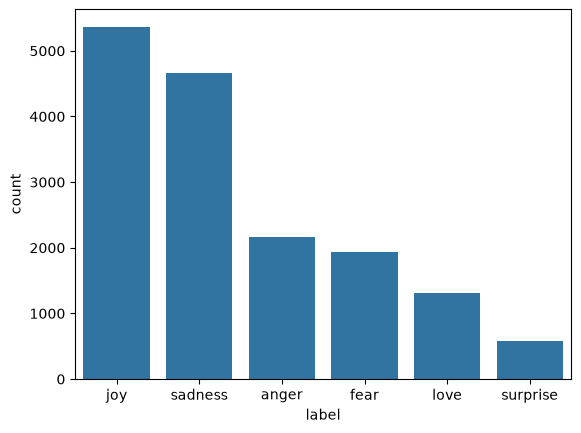

In [9]:
sns.countplot(x = 'label',data =df_train,order=df_train['label'].value_counts().index)

## 4. Data Preprocessing - Using NLP

tokenize text, pad sequences to max length 50, and convert lables to NumPy arrays

In [10]:

import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

max_words = 10000

tokenizer  = Tokenizer(num_words=max_words,oov_token='<un>')
tokenizer.fit_on_texts(df_train['text'])

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

pad_train_seqeuence = pad_sequences(train_sequence, maxlen=50 ,padding='post',truncating= 'post')
pad_test_seqeuence = pad_sequences(test_sequence, maxlen=50 ,padding='post',truncating= 'post')

train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))

print(f"Vacabulary Size:{len(tokenizer.word_index)}")
print(f"Max Sentences Length:{(pad_train_seqeuence.shape[1])}")

Vacabulary Size:15213
Max Sentences Length:50


###  5. shared Training Utilities
Compute balancced class weights to handle datasets  skew and setup early stopping


In [11]:
from sklearn.utils import class_weight
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes= np.unique(train_labels),
    y = train_labels
)

class_weight_dict  = dict(enumerate(class_weights))

In [12]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)

### 6. Phase-1 Plain Foundational Model
train plain(non-bidirectional ) Simple RNN , Standard LSTM, and Standard GRU Model

In [22]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Embedding(
        input_dim=max_words,
        output_dim=128,
        input_length=50
    ),
    SimpleRNN(units=128,return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    pad_train_seqeuence,
    train_labels,
    validation_data=(pad_test_seqeuence,test_labels),
    epochs=20,
    callbacks=[early_stopping],
    batch_size=32,
    class_weight=class_weight_dict
)
rnn_loss,rnn_accuracy = model.evaluate(pad_test_seqeuence,test_labels)
print(f"RNN Test Loss: {rnn_loss:.4f}")
print(f"RNN Test Accuracy: {rnn_accuracy:.4f}")

Epoch 1/20


c:\Users\DEV_MANISH\anaconda3\envs\deeplearn\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 29ms/step - accuracy: 0.1631 - loss: 1.9052 - val_accuracy: 0.1290 - val_loss: 1.8156
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.1538 - loss: 1.8065 - val_accuracy: 0.0835 - val_loss: 1.7987
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.1568 - loss: 1.7893 - val_accuracy: 0.1200 - val_loss: 1.7911
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.1573 - loss: 1.7778 - val_accuracy: 0.2075 - val_loss: 1.7733
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.1468 - loss: 1.7703 - val_accuracy: 0.1420 - val_loss: 1.7719
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.1431 - loss: 1.7663 - val_accuracy: 0.1280 - val_loss: 1.7949
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.1451 - loss: 1.7667 - val_accuracy: 0.1120 - val_loss: 1.7767
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.1400 - loss: 1.7682 - val_accurac

### 6.2  Model 2 --- Standard LSTM

In [24]:
## Standard LSTM Model
from tensorflow.keras.layers import Embedding, SimpleRNN, Dropout, Dense, LSTM
from tensorflow.keras.callbacks import EarlyStopping

lstm_model = Sequential([
    Embedding(
        input_dim=max_words,
        output_dim=128,
        input_length=50
    ),
    LSTM(units=128,return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)
history = lstm_model.fit(
    pad_train_seqeuence,
    train_labels,
    validation_data=(pad_test_seqeuence,test_labels),
    epochs=20,
    callbacks=[early_stopping],
    batch_size=32,
    class_weight=class_weight_dict
)
lstm_loss,lstm_accuracy = lstm_model.evaluate(pad_test_seqeuence,test_labels)
print(f"LSTM Test Loss: {lstm_loss:.4f}")
print(f"LSTM Test Accuracy: {lstm_accuracy:.4f}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 43ms/step - accuracy: 0.1564 - loss: 1.7954 - val_accuracy: 0.1150 - val_loss: 1.8014
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 49ms/step - accuracy: 0.1634 - loss: 1.7935 - val_accuracy: 0.1440 - val_loss: 1.7834
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 50ms/step - accuracy: 0.1714 - loss: 1.7930 - val_accuracy: 0.0385 - val_loss: 1.7974
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 49ms/step - accuracy: 0.1781 - loss: 1.7915 - val_accuracy: 0.1845 - val_loss: 1.7025
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.2074 - loss: 1.7830 - val_accuracy: 0.1410 - val_loss: 1.8317
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 43ms/step - accuracy: 0.2707 - loss: 1.6202 - val_accuracy: 0.3210 - val_loss: 1.5002
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.2979 - loss: 1.4542 - val_accuracy: 0.2900 - val_loss: 1.7617
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 45ms/step - accuracy: 0.3061 - loss: 1.4424 - 

### 6.3 Model 3 --- Standard GRU Model
Plain stackd GAted Recurrent Unit Network

In [26]:
## Standard LSTM Model
from tensorflow.keras.layers import Embedding, SimpleRNN, Dropout, Dense, LSTM,GRU
from tensorflow.keras.callbacks import EarlyStopping

gru_model = Sequential([
    Embedding(
        input_dim=max_words,
        output_dim=128,
        input_length=50
    ),
    GRU(units=128,return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

gru_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)
history = gru_model.fit(
    pad_train_seqeuence,
    train_labels,
    validation_data=(pad_test_seqeuence,test_labels),
    epochs=20,
    callbacks=[early_stopping],
    batch_size=32,
    class_weight=class_weight_dict
)
gru_loss,gru_accuracy = gru_model.evaluate(pad_test_seqeuence,test_labels)
print(f"GRU Test Loss: {gru_loss:.4f}")
print(f"GRU Test Accuracy: {gru_accuracy:.4f}")

Epoch 1/20


c:\Users\DEV_MANISH\anaconda3\envs\deeplearn\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 52ms/step - accuracy: 0.1677 - loss: 1.7968 - val_accuracy: 0.0795 - val_loss: 1.8040
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 55ms/step - accuracy: 0.1507 - loss: 1.7950 - val_accuracy: 0.0330 - val_loss: 1.8054
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 49ms/step - accuracy: 0.1504 - loss: 1.7947 - val_accuracy: 0.0325 - val_loss: 1.8159
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 24s 48ms/step - accuracy: 0.1447 - loss: 1.7930 - val_accuracy: 0.0335 - val_loss: 1.8059
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.0795 - loss: 1.8040
GRU Test Loss: 1.8040
GRU Test Accuracy: 0.0795


### 6.4 Phase 1 Ranking & Selection 
Rank foundatioonla models to pick the bst base cell for phase 2

In [29]:
## Ranking and selection

result_df = pd.DataFrame({
    'model':['RNN','LSTM','GRU'],
    'test_loss':[rnn_loss,lstm_loss,gru_loss],
    'test_accuracy':[rnn_accuracy,lstm_accuracy,gru_accuracy],
    
    
}).sort_values(by='test_accuracy',ascending=False).reset_index(drop=True)

result_df   

,model,test_loss,test_accuracy
0,LSTM,0.301397,0.9035
1,RNN,1.771931,0.1420
2,GRU,1.804039,0.0795


### 7. Phase 2--- Advanced bidirectional GRU
Enhace Gru with Bidirectional layers, 300D embedding, and 0.5 droupout. regularization

##### 7.1 Model 4  -- Advanced STacked Bidirectional GRU

In [36]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(
        input_dim=max_words,
        output_dim=300,
        input_length=50
    ),
    Bidirectional(GRU(units=128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(units=64)),
    Dropout(0.5),
    Dense(units=num_classes, activation="softmax")
])

BiGRU.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)


history = BiGRU.fit(
    pad_train_seqeuence,
    train_labels,
    validation_data=(pad_test_seqeuence,test_labels),
    epochs=20,
    callbacks=[early_stopping],
    batch_size=32,
    class_weight=class_weight_dict
)
BiGRU.summary()

gru_loss,gru_accuracy = BiGRU.evaluate(pad_test_seqeuence,test_labels)
print(f"GRU Test Loss: {gru_loss:.4f}")
print(f"GRU Test Accuracy: {gru_accuracy:.4f}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 55s 86ms/step - accuracy: 0.5847 - loss: 1.0304 - val_accuracy: 0.8985 - val_loss: 0.2881
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.9171 - loss: 0.2455 - val_accuracy: 0.9005 - val_loss: 0.3249
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.9454 - loss: 0.1452 - val_accuracy: 0.9185 - val_loss: 0.1997
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 44s 88ms/step - accuracy: 0.9604 - loss: 0.1097 - val_accuracy: 0.9100 - val_loss: 0.3098
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 58s 115ms/step - accuracy: 0.9688 - loss: 0.0868 - val_accuracy: 0.9205 - val_loss: 0.2498
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 68s 87ms/step - accuracy: 0.9741 - loss: 0.0735 - val_accuracy: 0.9250 - val_loss: 0.2675


Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_17 (Embedding)        │ (32, 50, 300)          │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (32, 50, 256)          │       330,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (32, 50, 256)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (32, 128)              │       123,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (32, 128)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (32, 6)                │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,363,988 (39.54 MB)

 Trainable params: 3,454,662 (13.18 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,909,326 (26.36 MB)

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.9185 - loss: 0.1997
GRU Test Loss: 0.1997
GRU Test Accuracy: 0.9185


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step


<Axes: >

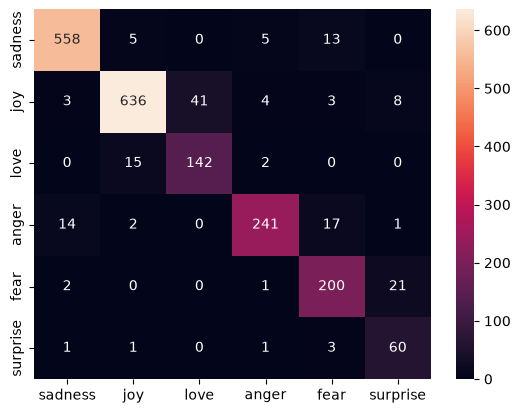

In [42]:
from sklearn.metrics import confusion_matrix

true_labels = test_labels
predicted_labels = BiGRU.predict(pad_test_seqeuence).argmax(axis=1)
sns.heatmap(confusion_matrix(true_labels, predicted_labels), annot=True, fmt='d',xticklabels=label_names, yticklabels=label_names)



#####  9. Final Predictions

In [43]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

In [55]:
sample_sequences = tokenizer.texts_to_sequences(sample_texts)

simple_padded_sequence = pad_sequences(
    sample_sequences,
    maxlen=50,
    padding="post",
    truncating="post"
)

# Predict only once
prediction_probs = BiGRU.predict(
    simple_padded_sequence,
    verbose=0
)

sample_predictions = np.argmax(prediction_probs, axis=1)

for i, text in enumerate(sample_texts):
    predicted_index = sample_predictions[i]

    print(f"Text: {text}")
    print(f"Predicted Emotion: {label_names[predicted_index]}")
    print(f"Confidence: {prediction_probs[i][predicted_index]:.2%}")
    print()

Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: fear
Confidence: 58.60%

Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Confidence: 99.80%

Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Confidence: 86.15%

Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Confidence: 99.73%

Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise
Confidence: 98.92%



In [60]:
## 10.save Model & Tokenizer

import os
import joblib
import pickle

model_dir  = "Artifacts"
os.makedirs(model_dir, exist_ok=True)

## save bigru model
BiGRU.save(os.path.join(model_dir,"BiGRU_model.keras"))

## save tokenizer
with open(os.path.join(model_dir, "tokenizer.pkl"), "wb") as f:
    pickle.dump(tokenizer, f)
